<a href="https://colab.research.google.com/github/thanh-huy/SIC_Excercies/blob/main/ex_0802.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bài tập lập trình #1002 – Fine-Tuning BERT phân loại tài liệu doanh nghiệp
**Chapter 10 · Bài 2.3 (slide 52 – 71)**

Quy trình 8 bước: Load Dataset → Pre-Processing → Tokenization → Load Pre-Trained Model → Training Arguments → Fine-Tune (Trainer) → Evaluate → Save the model.

Mô hình nền: `bert-base-uncased` (12 lớp, 110 triệu tham số). Dữ liệu: *Company Documents Dataset* (Kaggle), 4 lớp tài liệu.
> Bật GPU (`Runtime → Change runtime type → T4 GPU`) trước khi chạy.

In [1]:
# Install only what is missing, into THIS kernel's environment (never touches torch).
# Local venv: prefer `pip install -r requirements-cuda.txt` once, then this cell does nothing.
import importlib.util, subprocess, sys
_need = {"transformers": "transformers", "datasets": "datasets", "accelerate": "accelerate", "sklearn": "scikit-learn", "seaborn": "seaborn", "tensorboard": "tensorboard"}
_missing = [pip for mod, pip in _need.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])
print("missing packages installed:", _missing or "none")

missing packages installed: none


In [2]:
import torch
print("torch", torch.__version__, "| built for CUDA", torch.version.cuda)
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} | compute capability {p.major}.{p.minor} | VRAM {p.total_memory/2**30:.1f} GiB | bf16: {torch.cuda.is_bf16_supported()}")
else:
    print("CUDA NOT available -> everything below runs on CPU.")
    print("Check `nvidia-smi` and that the torch CUDA build (see line above) is supported by your driver.")

torch 2.11.0+cu130 | built for CUDA 13.0
GPU: Tesla T4 | compute capability 7.5 | VRAM 14.6 GiB | bf16: True


## (1) Tải bộ dữ liệu – Load Dataset (slide 55 – 60)
Nhập các thư viện cần thiết.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# `google.colab` chỉ có trên Colab; ở máy local thì bỏ qua
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
from sklearn.model_selection import train_test_split
from sklearn.metrics import *
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import load_dataset, Dataset

**Thiết lập thiết bị tính toán** – `torch.device` tự chọn GPU (`cuda`) nếu có, nếu không dùng CPU. Mô hình và dữ liệu phải nằm trên cùng một thiết bị.

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


Tải tệp `company-document-text.csv` (Kaggle – Company Documents Dataset: 4 loại tài liệu *invoice, report, ShippingOrder, purchase order*).
* Trên Colab: chọn **Choose Files** để upload.
* Chạy local: đặt tệp CSV cùng thư mục với notebook (sửa `data_path` nếu tên khác).

In [5]:
if IN_COLAB:
    uploaded = files.upload()
    data_path = list(uploaded.keys())[0]
else:
    data_path = "company-document-text.csv"

data = pd.read_csv(data_path)
data.head()

Saving emotions.csv to emotions.csv


,text,label,label_name
0,i didnt feel humiliated,0,sadness
1,i can go from feeling so hopeless to so damned...,0,sadness
2,im grabbing a minute to post i feel greedy wrong,3,anger
3,i am ever feeling nostalgic about the fireplac...,2,love
4,i am feeling grouchy,3,anger


> **Dùng bộ dữ liệu khác (ví dụ `emotions.csv`, 6 cảm xúc)?** Bộ này có cột `label` (số) và `label_name` (tên). Chạy ô dưới để dùng tên cảm xúc làm nhãn; phần còn lại của notebook không cần sửa vì `num_labels` được lấy từ dữ liệu. Với bộ dữ liệu company-documents thì ô này tự bỏ qua.

In [6]:
if "label_name" in data.columns:      # emotions.csv
    data["label"] = data["label_name"]
print(data.shape)
data["label"].value_counts()

(16000, 3)


,count
label,
joy,5362
sadness,4666
anger,2159
fear,1937
love,1304
surprise,572


Phân bố của từng danh mục nhãn (slide 59):

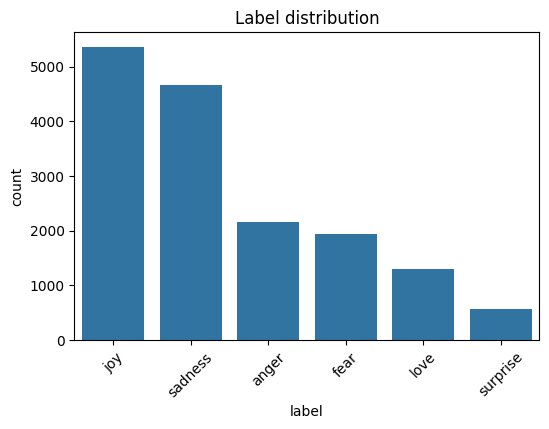

In [7]:
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x="label", order=data["label"].value_counts().index)
plt.xticks(rotation=45)
plt.title("Label distribution")
plt.show()

Độ dài văn bản (slide 60): cột `word_count` không dùng trực tiếp để huấn luyện nhưng giúp chọn `max_length` khi tokenization. Với bộ company-documents, hầu hết văn bản dài khoảng 130 từ.

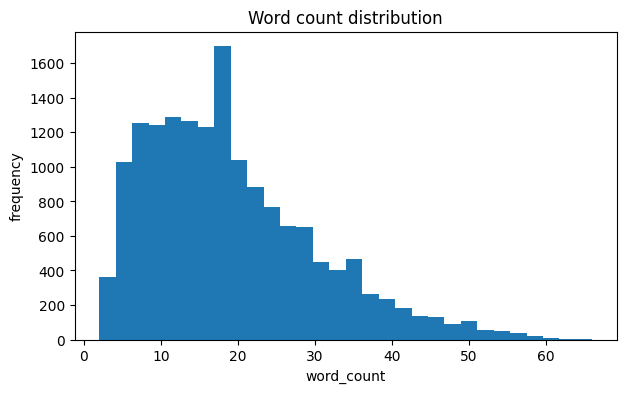

count    16000.000000
mean        19.166313
std         10.986905
min          2.000000
25%         11.000000
50%         17.000000
75%         25.000000
max         66.000000
Name: word_count, dtype: float64


In [8]:
if "word_count" not in data.columns:
    data["word_count"] = data["text"].str.split().str.len()

plt.figure(figsize=(7, 4))
plt.hist(data["word_count"], bins=30)
plt.xlabel("word_count")
plt.ylabel("frequency")
plt.title("Word count distribution")
plt.show()
print(data["word_count"].describe())

## (2) Tiền xử lý dữ liệu – Pre-Processing (slide 61 – 62)
**Integer encoding** cho cột nhãn bằng `LabelEncoder` (bước thiết yếu cho phân loại đa lớp).

In [9]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
data['label'] = le.fit_transform(data['label'])
print(dict(zip(le.classes_, le.transform(le.classes_))))
data.head()

{'anger': np.int64(0), 'fear': np.int64(1), 'joy': np.int64(2), 'love': np.int64(3), 'sadness': np.int64(4), 'surprise': np.int64(5)}


,text,label,label_name,word_count
0,i didnt feel humiliated,4,sadness,4
1,i can go from feeling so hopeless to so damned...,4,sadness,21
2,im grabbing a minute to post i feel greedy wrong,0,anger,10
3,i am ever feeling nostalgic about the fireplac...,3,love,18
4,i am feeling grouchy,0,anger,4


Giữ lại các cột cần thiết, chia **train / validation (70/30)** rồi chuyển sang `Dataset` (tensor dataset) của Hugging Face.

In [10]:
data2 = data.loc[:, ['text','label']].copy()
train, val = train_test_split(data2, test_size=0.3, random_state=10)

train_ds = Dataset.from_pandas(train, preserve_index=False)
val_ds = Dataset.from_pandas(val, preserve_index=False)
print(train_ds)
print(val_ds)

Dataset({
    features: ['text', 'label'],
    num_rows: 11200
})
Dataset({
    features: ['text', 'label'],
    num_rows: 4800
})


## (3) Mã hóa văn bản – Tokenization (slide 63 – 64)
Tải tokenizer tương ứng với mô hình. `max_length = 130` (từ phân tích độ dài ở trên): câu dài hơn bị cắt (*truncation*), câu ngắn hơn được đệm số 0 (*padding*).
> Với `emotions.csv` (≤ 66 từ) có thể đặt `MAX_LENGTH = 64` để huấn luyện nhanh hơn.

In [11]:
model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

MAX_LENGTH = 130

def preprocess_function(data):
    return tokenizer(data['text'], padding="max_length", truncation=True, max_length=MAX_LENGTH)

train_ds = train_ds.map(preprocess_function, batched=True)
val_ds = val_ds.map(preprocess_function, batched=True)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/11200 [00:00<?, ? examples/s]

Map:   0%|          | 0/4800 [00:00<?, ? examples/s]

Sau khi tokenize, văn bản trở thành `input_ids` và `attention_mask` (slide 64). Padding giúp mọi mẫu trong batch có cùng độ dài.

In [12]:
sample = train_ds[0]
print(sample.keys())
print("input_ids     :", sample['input_ids'][:20], "...")
print("attention_mask:", sample['attention_mask'][:20], "...")
print(tokenizer.convert_ids_to_tokens(sample['input_ids'][:20]))

dict_keys(['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'])
input_ids     : [101, 1045, 2572, 2061, 7653, 1998, 7568, 1998, 1045, 2514, 9657, 2153, 102, 0, 0, 0, 0, 0, 0, 0] ...
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0] ...
['[CLS]', 'i', 'am', 'so', 'relieved', 'and', 'excited', 'and', 'i', 'feel', 'confident', 'again', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']


## (4) Tải mô hình huấn luyện sẵn – Load Pre-Trained Model (slide 65)
`num_labels` là số lớp đầu ra: **4** với company-documents (ở đây lấy từ dữ liệu: `len(le.classes_)`).

In [13]:
num_labels = len(le.classes_)   # = 4 for company-document-text.csv
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=num_labels)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## (5) Thiết lập tham số huấn luyện – Training Arguments (slide 66)

In [14]:
import os
os.environ["TENSORBOARD_LOGGING_DIR"] = "./logs"   # TensorBoard log directory (replaces `logging_dir`, removed in transformers v5)

args = TrainingArguments(
    output_dir = './results',          # where to save checkpoints/outputs
    eval_strategy = "epoch",           # run eval at the end of each epoch
    save_strategy = "epoch",           # save a checkpoint every epoch
    learning_rate = 2e-5,              # base learning rate
    per_device_train_batch_size = 32,  # train batch size per device
    per_device_eval_batch_size = 32,   # eval batch size per device
    num_train_epochs  = 3,             # total training epochs
    weight_decay = 0.02,               # L2 weight decay strength
    load_best_model_at_end = True,     # reload best checkpoint (by metric)
    logging_steps = 10,                # log every N training steps
    report_to="tensorboard"            # send logs to TensorBoard
)

## (6) Tinh chỉnh mô hình – Fine-Tune (slide 67)
`Trainer` quản lý vòng lặp huấn luyện theo các siêu tham số ở trên. (Từ phiên bản `transformers` mới, đối số `tokenizer=` đã được đổi thành `processing_class=`.)

In [15]:
trainer = Trainer(
    model = model,
    args = args,                  # TrainingArguments
    train_dataset = train_ds,
    eval_dataset = val_ds,
    processing_class = tokenizer, # (older versions: tokenizer = tokenizer)
)
trainer.train()

Epoch,Training Loss,Validation Loss
1,0.338197,0.269005
2,0.144945,0.179350
3,0.118152,0.169565


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

TrainOutput(global_step=1050, training_loss=0.36952231685320536, metrics={'train_runtime': 944.3331, 'train_samples_per_second': 35.581, 'train_steps_per_second': 1.112, 'total_flos': 2244746806848000.0, 'train_loss': 0.36952231685320536, 'epoch': 3.0})

## (7) Đánh giá – Evaluate (slide 68 – 69)
Dự báo trên tập validation, rồi đánh giá bằng `confusion_matrix` và `classification_report` của scikit-learn.

In [16]:
pred_out = trainer.predict(val_ds)           # Run inference on the validation dataset
pred = pred_out.predictions.argmax(axis=-1)  # Select the predicted class with the highest logit

print(confusion_matrix(val_ds['label'], pred))
print(classification_report(val_ds['label'], pred, target_names = le.classes_))

[[ 595   19    4    1   12    0]
 [  21  502    4    1   12   45]
 [   4    4 1501   60   12   17]
 [   0    0   59  341    3    0]
 [  24    9   10    2 1372    2]
 [   0    7    1    0    0  156]]
              precision    recall  f1-score   support

       anger       0.92      0.94      0.93       631
        fear       0.93      0.86      0.89       585
         joy       0.95      0.94      0.94      1598
        love       0.84      0.85      0.84       403
     sadness       0.97      0.97      0.97      1419
    surprise       0.71      0.95      0.81       164

    accuracy                           0.93      4800
   macro avg       0.89      0.92      0.90      4800
weighted avg       0.93      0.93      0.93      4800



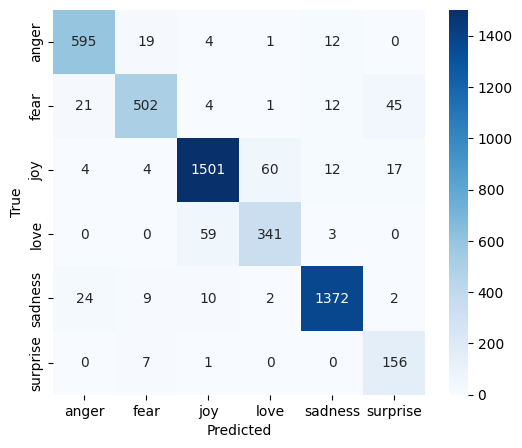

In [17]:
# (Tùy chọn) Vẽ ma trận nhầm lẫn dạng heatmap
cm = confusion_matrix(val_ds['label'], pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.show()

**Cách đọc kết quả** (với company-documents, slide 69): accuracy tổng thể ≈ 95%; có nhầm lẫn nhẹ giữa *Invoice* và *Purchase Order* do thuật ngữ trùng lặp; lớp *Report* thấp hơn một chút do ít mẫu hơn (support = 62); precision/recall cao đều ở mọi lớp → không có dấu hiệu overfitting.

## (8) Lưu mô hình – Save the model (slide 70 – 71)
Lưu mô hình và tokenizer đã fine-tune. Thư mục sẽ chứa: `config.json` (cấu trúc & siêu tham số), `tokenizer_config.json`, `tokenizer.json` (tokenizer tuần tự hóa đầy đủ), tệp trọng số (`model.safetensors`) và – tùy phiên bản `transformers` – thêm `special_tokens_map.json` (`[CLS]`, `[SEP]`, `[PAD]`…), `vocab.txt`, `added_tokens.json` (nếu có). Slide liệt kê 6 tệp tokenizer/cấu hình của `transformers` v4; bản v5 gộp bớt nên bạn sẽ thấy ít tệp hơn.

In [18]:
import os
fine_tuned_path = 'model'                      # Set the folder name for saving the model and tokenizer
model.save_pretrained(fine_tuned_path)         # Save the trained model to the specified directory
tokenizer.save_pretrained(fine_tuned_path)     # Save the tokenizer to the same directory
print(sorted(os.listdir(fine_tuned_path)))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']


Tải lại mô hình và tokenizer đã lưu rồi dự đoán một câu mới.

In [19]:
model2 = AutoModelForSequenceClassification.from_pretrained(fine_tuned_path)
tokenizer2 = AutoTokenizer.from_pretrained(fine_tuned_path)
model2.eval()

# Example sentence (a shipping/inventory style document). Replace it with a sentence from your own dataset if needed.
sentence = 'mario pontes products product id  product  quantity  unit price  10 ikura 70 31 31'
inputs = tokenizer2(sentence, return_tensors="pt")  # Tokenize sentence and convert to PyTorch tensors
with torch.no_grad():
    outputs = model2(**inputs)                      # Perform forward pass with the model
logits = outputs.logits                             # Retrieve raw prediction scores (logits)
prob = logits.softmax(dim=-1)                       # Convert logits to probabilities using softmax
pred = prob.argmax(dim=-1).item()                   # Get the index of the class with the highest probability
label_list = le.classes_                            # List of class names from label encoder
print("Predicted class name:", label_list[pred])    # Print predicted class label name
print("Probabilities:", prob.tolist()[0])           # Print predicted class probabilities

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Predicted class name: joy
Probabilities: [0.23000113666057587, 0.0380595400929451, 0.5033285021781921, 0.012772826477885246, 0.20759887993335724, 0.008239143528044224]
